# Exploración y Agrupación de Clientes de un Banco

En este notebook trabajamos con información básica de clientes bancarios. Vamos a analizar variables como la edad, los ingresos y la experiencia laboral para agrupar a los clientes usando técnicas de análisis de datos. También aplicamos reducción de dimensiones (PCA) y agrupamiento (K-Means) para encontrar patrones interesantes en los datos.

> **Nota:** dataset ficticio de 8 clientes bancarios, creado para practicar la técnica. Sirve para ilustrar el procedimiento, no para sacar conclusiones generalizables.

## Preparativos iniciales

Primero importamos las bibliotecas necesarias y configuramos el entorno de trabajo para guardar los resultados si es necesario.

In [ ]:
# Importar bibliotecas
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import os
# Carpeta local donde se guardan los gráficos
output_dir = 'output'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# Crear DataFrame
df = pd.DataFrame({
    "Cliente": [1, 2, 3, 4, 5, 6, 7, 8],
    "Edad": [25, 40, 35, 50, 30, 45, 38, 29],
    "Ingresos": [50000, 60000, 70000, 80000, 45000, 85000, 72000, 48000],
    "Experiencia": [2, 10, 7, 15, 3, 20, 12, 4],
    "Estado_Cuenta": ["Pagado", "Moroso", "Pagado", "Moroso", "Pagado", "Pagado", "Pagado", "Pagado"]
})



Configuramos el estilo visual de los gráficos  y mostramos los resultados.

In [ ]:
# Configurar estilo visual de los gráficos
sns.set(style="whitegrid", palette="pastel", font_scale=1.2)
plt.rcParams['figure.figsize'] = [10, 6]
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

# Función para aplicar formato condicional
def highlight_moroso(s):
    return ['background-color: #ffcccc' if v == 'Moroso' else '' for v in s]

# Estilizar el DataFrame
styled_df = df.style.set_caption('Tabla de Clientes Bancarios')\
    .set_table_styles([
        {'selector': 'caption', 'props': [('font-size', '16px'), ('font-weight', 'bold'), ('color', '#333333')]},
        {'selector': 'th', 'props': [('background-color', '#4B0082'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center'), ('padding', '8px')]},
        {'selector': 'td', 'props': [('border', '1px solid #dddddd'), ('padding', '8px'), ('text-align', 'center')]},
        {'selector': 'tr:nth-child(even)', 'props': [('background-color', '#f9f9f9')]},
        {'selector': 'tr:hover', 'props': [('background-color', '#e0e0e0')]}
    ])\
    .apply(highlight_moroso, subset=['Estado_Cuenta'])\
    .format({
        'Ingresos': '${:,.0f}',  # Formato de moneda para Ingresos
        'Edad': '{:.0f}',        # Sin decimales para Edad
        'Experiencia': '{:.0f}'  # Sin decimales para Experiencia
    })

# Mostrar la tabla estilizada
from IPython.display import display
display(styled_df)

# Guardar la tabla como HTML
html_file = os.path.join(output_dir, 'tabla_estilizada.html')
styled_df.to_html(html_file)

# Opcional: guardar la tabla como imagen (requiere: pip install dataframe_image)
try:
    import dataframe_image as dfi
    png_file = os.path.join(output_dir, 'tabla_estilizada.png')
    dfi.export(styled_df, png_file, table_conversion='matplotlib')
except ImportError:
    print("dataframe_image no está instalado: se omite la exportación a PNG.")


,Cliente,Edad,Ingresos,Experiencia,Estado_Cuenta
0,1,25,"$50,000",2,Pagado
1,2,40,"$60,000",10,Moroso
2,3,35,"$70,000",7,Pagado
3,4,50,"$80,000",15,Moroso
4,5,30,"$45,000",3,Pagado
5,6,45,"$85,000",20,Pagado
6,7,38,"$72,000",12,Pagado
7,8,29,"$48,000",4,Pagado


## Tarea 1: Análisis Exploratorio de Datos (EDA)

### 1.1 Histogramas de Edad e Ingresos

Generamos histogramas para analizar la distribución de las variables **Edad** e **Ingresos**.

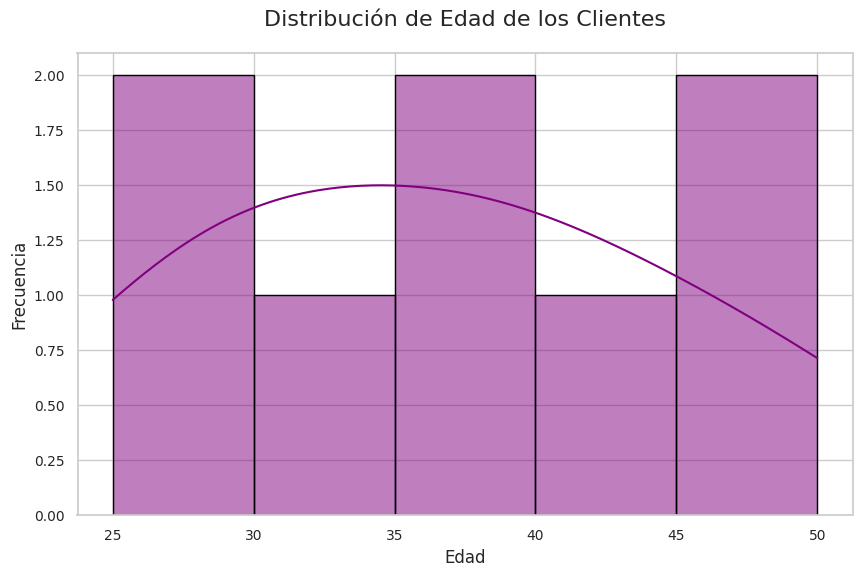

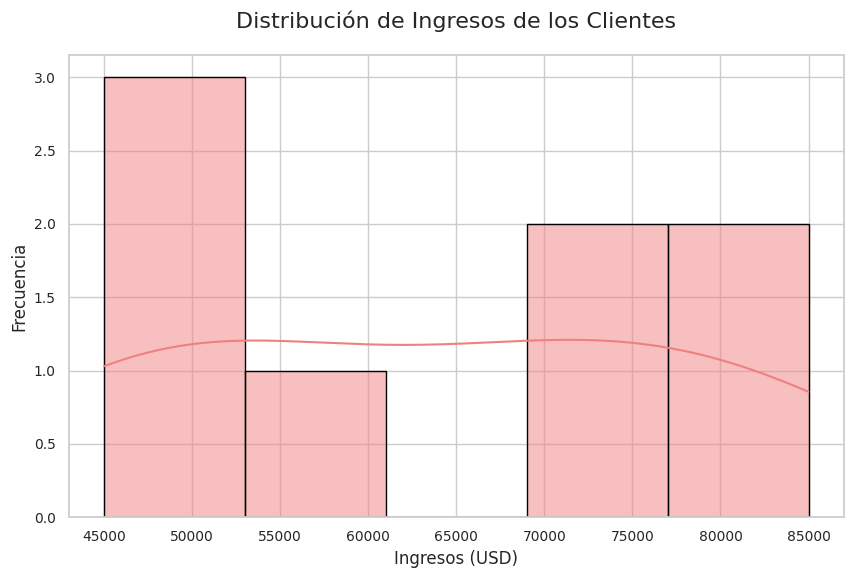

In [ ]:
# Histograma de Edad
sns.histplot(df['Edad'], bins=5, kde=True, color='purple', edgecolor='black', )
plt.title('Distribución de Edad de los Clientes', pad=20)
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.savefig(os.path.join(output_dir, 'histograma_edad.png'), bbox_inches='tight')
plt.show()

# Histograma de Ingresos
sns.histplot(df['Ingresos'], bins=5, kde=True, color='lightcoral', edgecolor='black')
plt.title('Distribución de Ingresos de los Clientes', pad=20)
plt.xlabel('Ingresos (USD)')
plt.ylabel('Frecuencia')
plt.savefig(os.path.join(output_dir, 'histograma_ingresos.png'), bbox_inches='tight')
plt.show()

**Interpretación**:
- **Edad**: La distribución es ligeramente sesgada a la derecha, con mayor frecuencia en el rango de 25-40 años. La curva KDE sugiere una distribución multimodal debido al tamaño pequeño del dataset, sin una clara normalidad.
- **Ingresos**: La distribución muestra picos en los rangos de 45,000-50,000 y 70,000-85,000, con un leve sesgo a la izquierda. Esto indica heterogeneidad en los ingresos de los clientes.

### 1.2 Correlación entre Edad, Ingresos y Experiencia

Calculamos la matriz de correlación de Pearson para las variables numéricas y la visualizamos con un mapa de calor.

Matriz de Correlación:
                Edad  Ingresos  Experiencia
Edad         1.00000  0.872330     0.912120
Ingresos     0.87233  1.000000     0.928305
Experiencia  0.91212  0.928305     1.000000


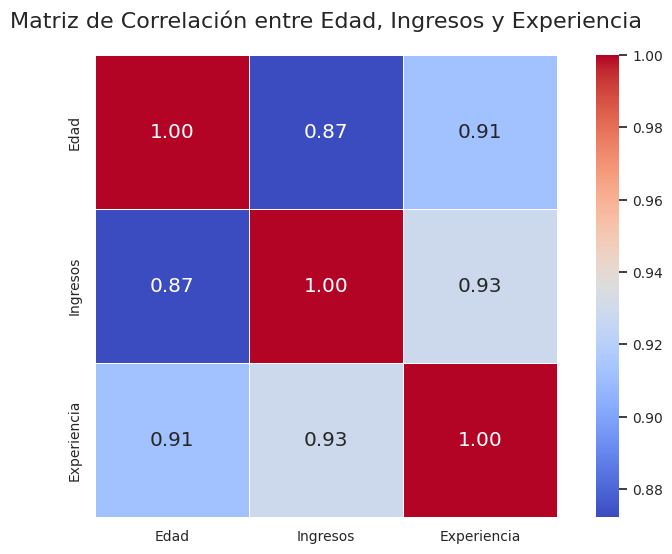

In [ ]:
# Seleccionar variables numéricas
df_numeric = df[['Edad', 'Ingresos', 'Experiencia']]

# Calcular matriz de correlación
correlation_matrix = df_numeric.corr()
print("Matriz de Correlación:")
print(correlation_matrix)

# Mapa de calor de correlación
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True, linewidths=0.5)
plt.title('Matriz de Correlación entre Edad, Ingresos y Experiencia', pad=20)
plt.savefig(os.path.join(output_dir, 'matriz_correlacion.png'), bbox_inches='tight')
plt.show()

**Interpretación**:
- **Edad e Ingresos**: correlación fuerte (r = 0.87): los clientes mayores tienden a tener mayores ingresos.
- **Edad y Experiencia**: correlación fuerte (r = 0.91), como era de esperar.
- **Ingresos y Experiencia**: es la correlación más fuerte de las tres (r = 0.93): mayor experiencia se asocia con mayores ingresos.
- Las tres variables están muy correlacionadas entre sí, lo que anticipa que PCA podrá resumirlas en muy pocas componentes.

### 1.3 Diagramas de Dispersión

Visualizamos las relaciones entre **Edad**, **Ingresos** y **Experiencia** con diagramas de dispersión, usando el estado de cuenta como color y el tamaño para una tercera variable.

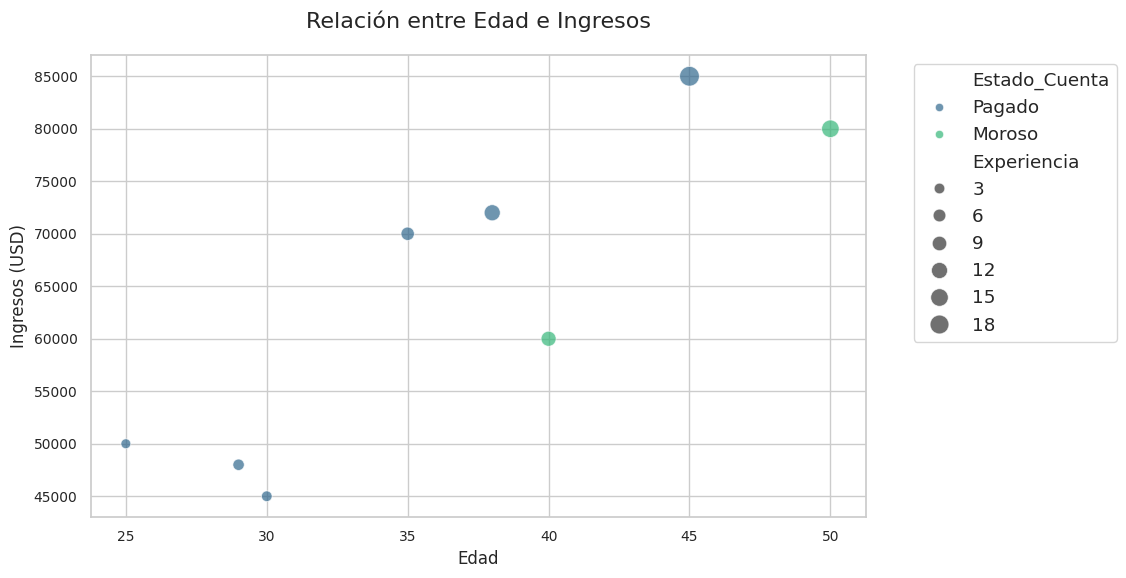

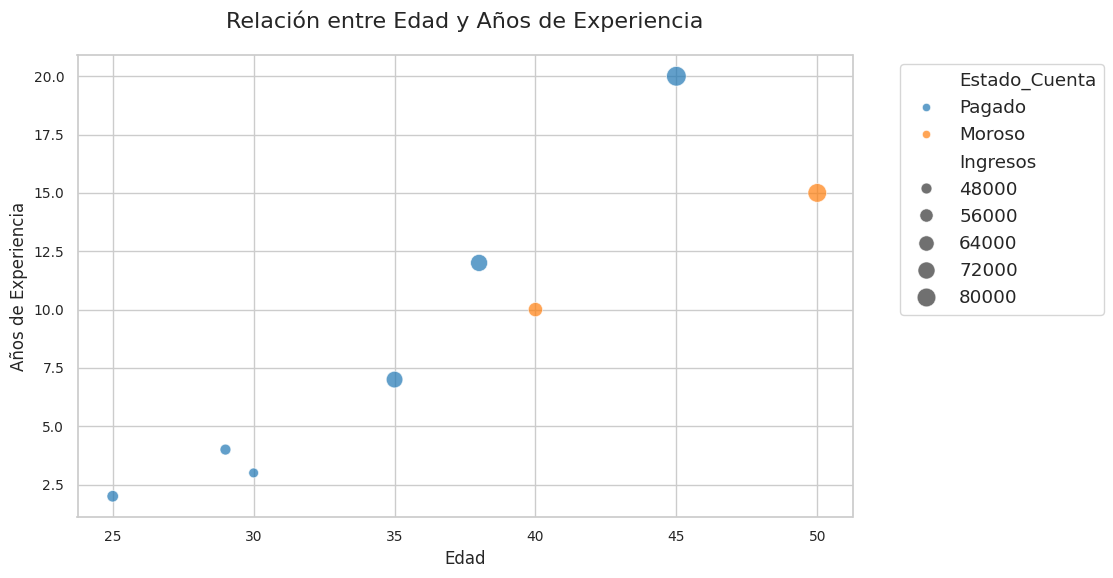

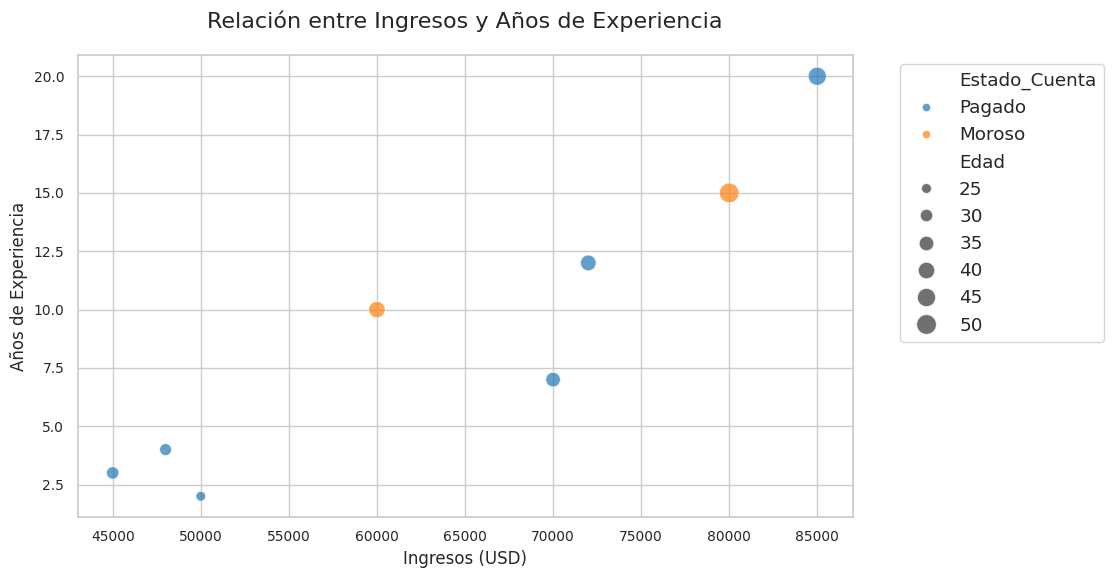

In [ ]:
# Diagrama de dispersión: Edad vs Ingresos
sns.scatterplot(x=df['Edad'], y=df['Ingresos'], hue=df['Estado_Cuenta'], size=df['Experiencia'],
                palette='viridis', sizes=(50, 200), alpha=0.7)
plt.title('Relación entre Edad e Ingresos', pad=20)
plt.xlabel('Edad')
plt.ylabel('Ingresos (USD)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig(os.path.join(output_dir, 'dispersión_edad_ingresos.png'), bbox_inches='tight')
plt.show()

# Diagrama de dispersión: Edad vs Experiencia
sns.scatterplot(x=df['Edad'], y=df['Experiencia'], hue=df['Estado_Cuenta'], size=df['Ingresos'],
                palette='tab10', sizes=(50, 200), alpha=0.7)
plt.title('Relación entre Edad y Edad de Experiencia', pad=20)
plt.xlabel('Edad')
plt.ylabel('Edad de Experiencia')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig(os.path.join(output_dir, 'dispersión_edad_experiencia.png'), bbox_inches='tight')
plt.show()

# Diagrama de dispersión: Ingresos vs Experiencia
sns.scatterplot(x=df['Ingresos'], y=df['Experiencia'], hue=df['Estado_Cuenta'], size=df['Edad'],
                palette='tab10', sizes=(50, 200), alpha=0.7)
plt.title('Relación entre Ingresos y Edad de Experiencia', pad=20)
plt.xlabel('Ingresos (USD)')
plt.ylabel('Edad de Experiencia')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig(os.path.join(output_dir, 'dispersión_ingresos_experiencia.png'), bbox_inches='tight')
plt.show()

**Interpretación**:
- **Edad vs Ingresos**: hay una tendencia positiva clara: los clientes mayores tienen mayores ingresos. Los clientes "Morosos" (2 y 4) tienen ingresos medios-altos (60,000 y 80,000).
- **Edad vs Experiencia**: relación fuerte, con una pequeña excepción: el cliente de 50 años (15 años de experiencia) tiene menos experiencia que el de 45 años (20).
- **Ingresos vs Experiencia**: tendencia positiva muy marcada; a mayor experiencia, mayores ingresos.

## Tarea 2: Aplicación de PCA para Reducción de Dimensionalidad

### 2.1 Normalización de los Datos

Normalizamos las variables numéricas para que tengan media 0 y desviación estándar 1 antes de aplicar PCA.

In [ ]:
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_numeric)
df_scaled = pd.DataFrame(df_scaled, columns=['Edad', 'Ingresos', 'Experiencia'])

### 2.2 Varianza Explicada por Componentes Principales

Calculamos cuántas componentes principales explican al menos el 90% de la varianza.

Varianza explicada por cada componente: [0.9362353  0.04299134 0.02077335]
Varianza acumulada: [0.9362353  0.97922665 1.        ]


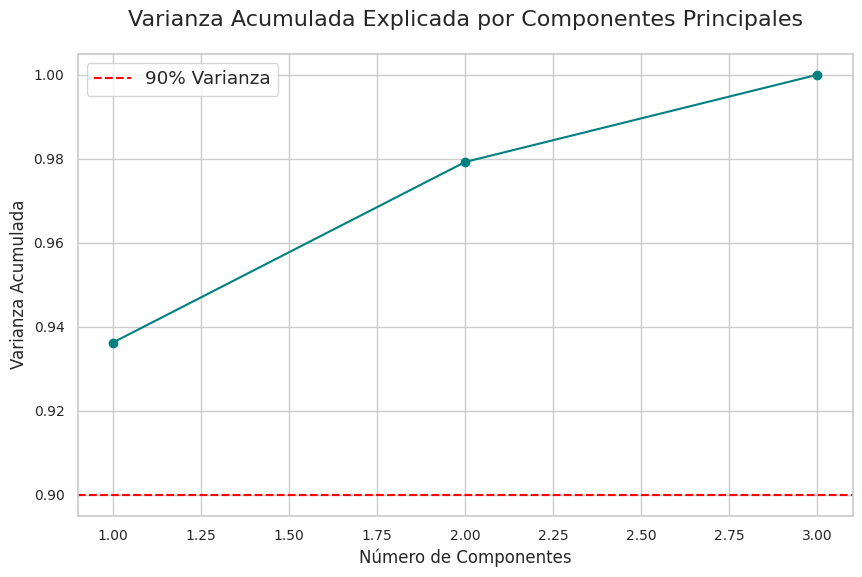

In [ ]:
pca = PCA()
pca.fit(df_scaled)
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = explained_variance_ratio.cumsum()

print("Varianza explicada por cada componente:", explained_variance_ratio)
print("Varianza acumulada:", cumulative_variance)

# Visualizar varianza acumulada
plt.plot(range(1, len(explained_variance_ratio) + 1), cumulative_variance, marker='o', linestyle='-', color='teal')
plt.title('Varianza Acumulada Explicada por Componentes Principales', pad=20)
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Acumulada')
plt.axhline(y=0.9, color='red', linestyle='--', label='90% Varianza')
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(output_dir, 'varianza_acumulada.png'), bbox_inches='tight')
plt.show()

**Interpretación**:
- La primera componente explica ~93.6 % de la varianza.
- Las dos primeras componentes explican ~97.9 %.
- Con una sola componente ya se supera el 90 %; se usan 2 para poder visualizar los datos en un plano sin perder prácticamente información.

### 2.3 Visualización en 2D con PCA

Proyectamos los datos en las dos primeras componentes principales.

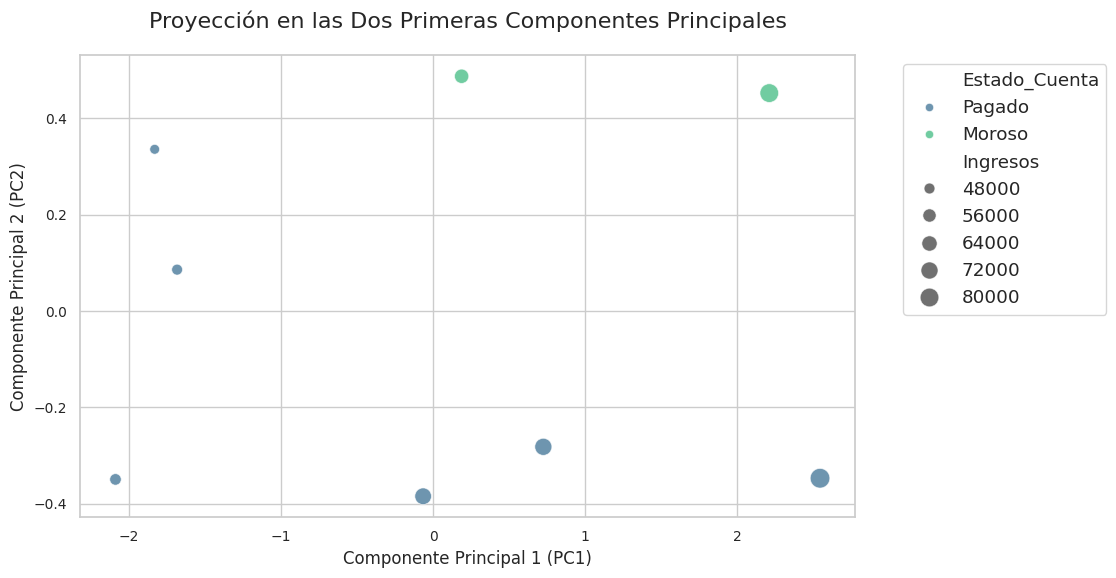

In [ ]:
pca = PCA(n_components=2)
df_pca = pca.fit_transform(df_scaled)
df_pca = pd.DataFrame(df_pca, columns=['PC1', 'PC2'])

sns.scatterplot(x=df_pca['PC1'], y=df_pca['PC2'], hue=df['Estado_Cuenta'], size=df['Ingresos'],
                palette='viridis', sizes=(50, 200), alpha=0.7)
plt.title('Proyección en las Dos Primeras Componentes Principales', pad=20)
plt.xlabel('Componente Principal 1 (PC1)')
plt.ylabel('Componente Principal 2 (PC2)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig(os.path.join(output_dir, 'proyección_pca.png'), bbox_inches='tight')
plt.show()

**Interpretación**:
- PC1 resume el "nivel" conjunto de edad, ingresos y experiencia: los clientes de menor perfil quedan a la izquierda y los de mayor perfil a la derecha.
- Los dos clientes morosos (2 y 4) tienen valores positivos de PC1, pero también hay un cliente que paga con el PC1 más alto (el 6). Por lo tanto, PC1 **no** separa por estado de cuenta; con solo 2 morosos no se puede concluir que PCA capture ese patrón.
- PC2 explica muy poca variabilidad (~4 %), por eso los puntos se dispersan poco en ese eje.

## Tarea 3: Segmentación de Clientes con Clustering

### 3.1 K-Means con Datos Originales

Aplicamos K-Means con 3 clusters sobre los datos normalizados.

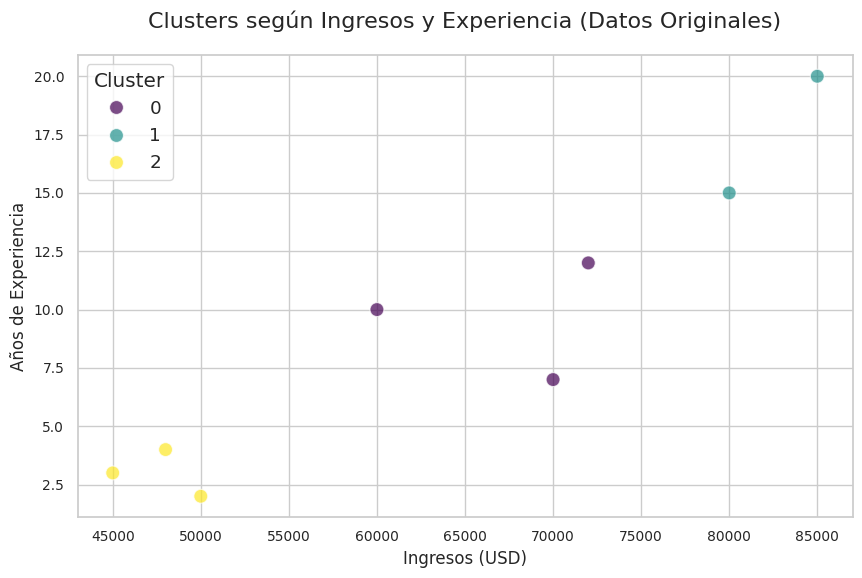

In [ ]:
kmeans_original = KMeans(n_clusters=3, random_state=42)
df['Cluster_Original'] = kmeans_original.fit_predict(df_scaled)

sns.scatterplot(x=df['Ingresos'], y=df['Experiencia'], hue=df['Cluster_Original'],
                palette='viridis', s=100, alpha=0.7)
plt.title('Clusters según Ingresos y Experiencia (Datos Originales)', pad=20)
plt.xlabel('Ingresos (USD)')
plt.ylabel('Edad de Experiencia')
plt.legend(title='Cluster')
plt.savefig(os.path.join(output_dir, 'clusters_originales.png'), bbox_inches='tight')
plt.show()

**Interpretación** (los números de cluster que asigna K-Means son arbitrarios y pueden variar entre ejecuciones; lo estable es la composición de los grupos):
- **Grupo de menor perfil**: clientes jóvenes con bajos ingresos y poca experiencia (clientes 1, 5, 8).
- **Grupo intermedio**: clientes de mediana edad con ingresos y experiencia intermedios (clientes 2, 3, 7).
- **Grupo de mayor perfil**: clientes mayores con altos ingresos y experiencia (clientes 4, 6).

### 3.2 K-Means con Datos Transformados por PCA

Aplicamos K-Means con 3 clusters sobre los datos transformados por PCA.

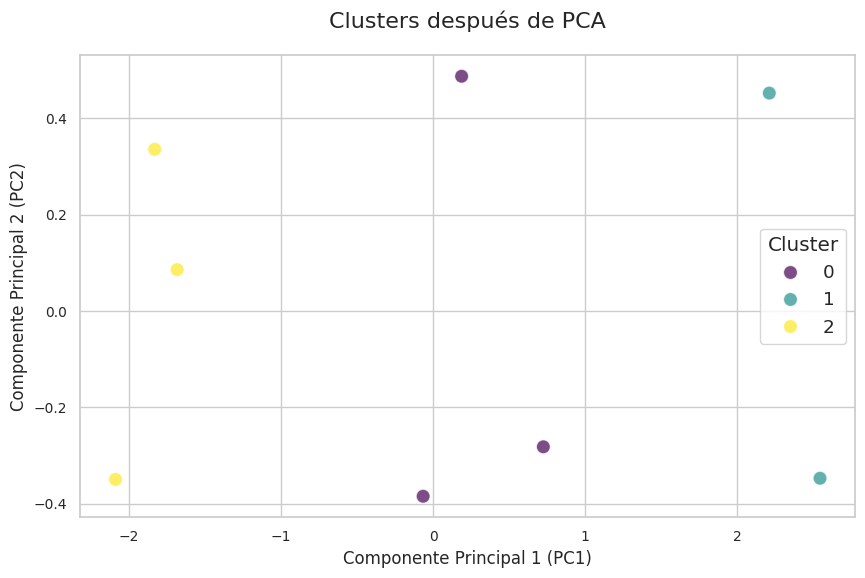

In [ ]:
kmeans_pca = KMeans(n_clusters=3, random_state=42)
df_pca['Cluster'] = kmeans_pca.fit_predict(df_pca)

sns.scatterplot(x=df_pca['PC1'], y=df_pca['PC2'], hue=df_pca['Cluster'],
                palette='viridis', s=100, alpha=0.7)
plt.title('Clusters después de PCA', pad=20)
plt.xlabel('Componente Principal 1 (PC1)')
plt.ylabel('Componente Principal 2 (PC2)')
plt.legend(title='Cluster')
plt.savefig(os.path.join(output_dir, 'clusters_pca.png'), bbox_inches='tight')
plt.show()

**Interpretación**:
- Los clusters son similares a los obtenidos con los datos originales, pero la visualización en el espacio PCA es más clara debido a la reducción de dimensionalidad.
- La separación entre clusters es más evidente, especialmente para el grupo de clientes con altos ingresos.

### Comparación de Resultados

- **Datos Originales**: Los clusters reflejan patrones en ingresos y experiencia, pero la visualización puede ser menos clara debido a las correlaciones entre variables.
- **Datos PCA**: La reducción de dimensionalidad elimina correlaciones redundantes, haciendo los clusters más compactos y fáciles de interpretar.

## Reflexión Final

- **Utilidad de PCA**: PCA fue efectivo para reducir la dimensionalidad, capturando el 97.9% de la varianza con 2 componentes (la primera sola ya explica el 93.6%), lo que facilitó la visualización sin pérdida significativa de información.
- **Diferencias en Clustering**: Los clusters en PCA son más claros visualmente, pero los grupos identificados son consistentes con los datos originales.
- **Rol de la IA**: Una consulta a una herramienta de IA sugirió técnicas como DBSCAN, clustering jerárquico y Gaussian Mixture Models, además de feature engineering (por ejemplo, ratio ingresos/experiencia). Estas ideas complementan el análisis y podrían mejorar la segmentación en futuros estudios.